1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN

In [10]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

2. CARGA Y CONSOLIDACIÓN DEL DATASET COMPLETO (RAW)

In [7]:
# Carga automatizada de todos los CSV contenidos en el ZIP oficial de la DNRPA
zip_path = '../data/raw/dnrpa-robos-recuperos-autos-2026.zip'

dfs = []
with zipfile.ZipFile(zip_path, 'r') as z:
    for filename in z.namelist():
        if filename.endswith('.csv'):
            with z.open(filename) as f:
                df_temp = pd.read_csv(f)
                dfs.append(df_temp)

df_raw = pd.concat(dfs, ignore_index=True)
print(f"Dimensiones consolidadas del dataset crudo: {df_raw.shape} filas, {df_raw.shape} columnas")

Dimensiones consolidadas del dataset crudo: (24718, 25) filas, (24718, 25) columnas


3. CONSTRUCCIÓN DE LA VARIABLE OBJETIVO (SIN RECORTE TEMPORAL)

In [11]:
# Abarca la totalidad del período.
# La variable objetivo 'recuperado' se genera directamente desde 'tramite_tipo':
# 1 = Trámites que contienen 'RECUPERO' | 0 = Otros trámites registrales (denuncias activas).

df = df_raw.copy()
df['recuperado'] = np.where(
    df['tramite_tipo'].str.contains('RECUPERO', case=False, na=False), 1, 0
)

# Cálculo dinámico de la proporción de clases sobre la base cruda inicial
distribucion_inicial = df['recuperado'].value_counts(normalize=True) * 100
pct_no_recuperado = distribucion_inicial.get(0, 0)
pct_recuperado = distribucion_inicial.get(1, 0)

print(f"\n--- Distribución inicial real de la variable objetivo ---")
print(f"No Recuperado / Otros trámites (0): {pct_no_recuperado:.2f}% ({df['recuperado'].value_counts()[0]} registros)")
print(f"Recuperado (1): {pct_recuperado:.2f}% ({df['recuperado'].value_counts()[1]} registros)")


--- Distribución inicial real de la variable objetivo ---
No Recuperado / Otros trámites (0): 94.92% (23463 registros)
Recuperado (1): 5.08% (1255 registros)


4. ANÁLISIS EXPLORATORIO DE DATOS (EDA)

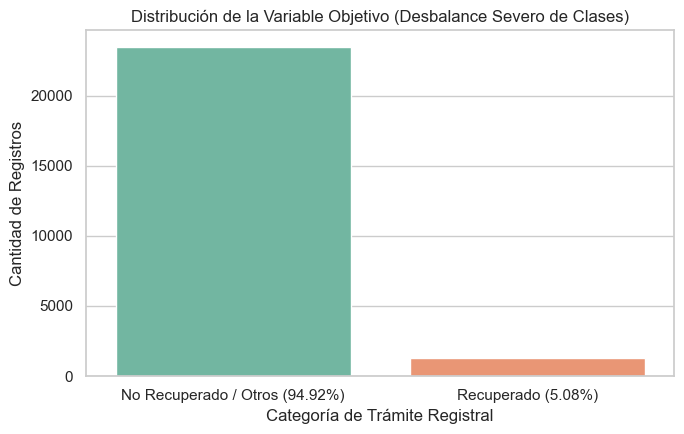

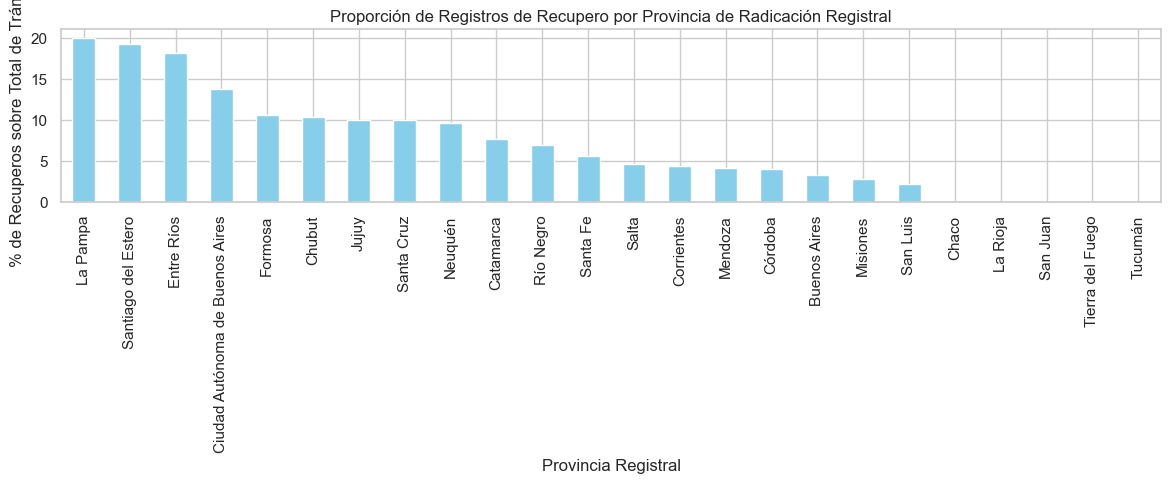


--- Conteo de Valores Faltantes (Nulos) por Variable ---
automotor_anio_modelo            48
automotor_origen                  0
automotor_tipo_descripcion        0
registro_seccional_provincia    493
recuperado                        0
dtype: int64


In [9]:
# A. Gráfico de distribución de clases con etiquetas calculadas dinámicamente
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=df, x='recuperado', hue='recuperado', palette='Set2', legend=False)
plt.title('Distribución de la Variable Objetivo (Desbalance Severo de Clases)')
plt.xlabel('Categoría de Trámite Registral')
plt.ylabel('Cantidad de Registros')
plt.xticks(
    [0, 1], 
    [f'No Recuperado / Otros ({pct_no_recuperado:.2f}%)', f'Recuperado ({pct_recuperado:.2f}%)']
)
plt.tight_layout()
plt.show()

# B. Proporción de registros de recupero según Provincia Registral
plt.figure(figsize=(12, 5))
prop_provincia = df.groupby('registro_seccional_provincia')['recuperado'].mean().sort_values(ascending=False) * 100
prop_provincia.plot(kind='bar', color='skyblue')
plt.title('Proporción de Registros de Recupero por Provincia de Radicación Registral')
plt.xlabel('Provincia Registral')
plt.ylabel('% de Recuperos sobre Total de Trámites')
plt.tight_layout()
plt.show()

# C. Revisión de variables predictoras conocidas al momento de la denuncia
columnas_modelo = [
    'automotor_anio_modelo', 
    'automotor_origen', 
    'automotor_tipo_descripcion', 
    'registro_seccional_provincia', 
    'recuperado'
]

print("\n--- Conteo de Valores Faltantes (Nulos) por Variable ---")
print(df[columnas_modelo].isnull().sum())



5. EXPORTACIÓN DEL DATASET PROCESADO FINAL

In [5]:
# Eliminación de nulos y selección estricta de columnas para modelado
df_processed = df[columnas_modelo].dropna().reset_index(drop=True)

print(f"\nDimensiones finales del dataset procesado: {df_processed.shape}")
print("\nDistribución final de clases post-limpieza:")
print(df_processed['recuperado'].value_counts(normalize=True).round(4) * 100)

# Guardado en la carpeta processed
df_processed.to_csv('../data/processed/dataset_recupero_automotores.csv', index=False)
print("\n✅ Dataset procesado guardado exitosamente en '../data/processed/dataset_recupero_automotores.csv'")


Dimensiones finales del dataset procesado: (24178, 5)

Distribución final de clases post-limpieza:
recuperado
0    94.88
1     5.12
Name: proportion, dtype: float64

✅ Dataset procesado guardado exitosamente en '../data/processed/dataset_recupero_automotores.csv'
